# 01 · Subscriber churn: what the data supports before any model

**Summary.** Cell2Cell has 51,047 subscribers, no duplicates and few true blanks. Missing values hide behind codes instead: handset
price is "Unknown" for 57%, and age and income are zero for a quarter. One field is mislabelled: `PercChangeMinutes`
is an absolute change in minutes, not a percentage. The README's driver claims reproduce exactly. Churn peaks at 12-17
months in service (33.6% vs 24.0% under 12 months); handsets 18+ months old churn at 34.0% vs 22.9% for handsets under
six months; retention-team callers churn at 45.0% vs 28.2%. Usage falling by half or more is the strongest behavioural
warning (40% vs 26% for stable usage). Two folk beliefs fail: more care calls go with *less* churn, and low credit
ratings churn less than high ones. Every signal is weak on its own (best single-feature AUC 0.57, best IV 0.14), so a
modest model AUC is a property of this data, not a modelling failure. Retention-team contact stays in the model,
because it is known before the churn window, but it is treated as a symptom. The sample over-represents churners (28.8%
vs an assumed 2% a month). Ranking metrics carry over to a real base; probabilities and money need a prior correction
first.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

## 1. Business understanding

| | |
|---|---|
| Decision | Which subscribers get a retention offer this month, and how many offers to fund |
| Unit | Subscriber (one row each; 51,047 subscribers of a US wireless carrier, anonymised) |
| Target | Churned in the observation window that follows the snapshot of usage, billing and care data |
| Action | Offer a retention deal (e.g. a handset upgrade or a bill credit) to the top *k*% of a ranked list |
| Success metric | Net retained revenue = saved churners x monthly revenue x months kept - offer spend |
| Money at stake | Churners in this sample bill $58 a month on average, so each save is worth about $700 a year in revenue |
| Constraints | Offer budget; no randomised retention test in the data (save rate unknown); the sample over-represents churners; the report's model uses no age, marital status, occupation or household data |

The data is Cell2Cell (Teradata Center for CRM, Duke University), distributed for academic use. It is not
redistributed here, and this notebook shows profiles and aggregates only, no subscriber rows.

In [2]:
d = F.load()
B = F.bands(d)
print(f"{len(d):,} subscribers, {d.shape[1] - 1} source columns; churn rate {d['Churned'].mean():.2%}; "
      f"mean monthly revenue ${d['MonthlyRevenue'].mean():.2f} (churners ${d.loc[d['Churned'] == 1, 'MonthlyRevenue'].mean():.2f})")
audit.duplicates(d.drop(columns=["Churned"]), key="CustomerID")

51,047 subscribers, 58 source columns; churn rate 28.82%; mean monthly revenue $58.83 (churners $58.00)


{'rows': 51047, 'exact_duplicate_rows': 0, 'duplicate_keys': 0}

## 2. Data audit

Profile of every source column (types, completeness, ranges).

In [3]:
prof = audit.profile(d.drop(columns=["CustomerID", "Churned"]))
prof

,dtype,non_null,missing_pct,unique,min,median,max,top,zeros_pct
column,,,,,,,,,
Churn,str,51047,0.0000,2,NaN,NaN,NaN,No,NaN
MonthlyRevenue,float64,50891,0.3100,12665,-6.1700,48.4600,"1,223.3800",NaN,0.0100
MonthlyMinutes,float64,50891,0.3100,2719,0.0000,366.0000,"7,359.0000",NaN,1.4200
TotalRecurringCharge,float64,50891,0.3100,214,-11.0000,45.0000,400.0000,NaN,0.3100
DirectorAssistedCalls,float64,50891,0.3100,146,0.0000,0.2500,159.3900,NaN,48.0200
OverageMinutes,float64,50891,0.3100,746,0.0000,3.0000,"4,321.0000",NaN,45.5700
RoamingCalls,float64,50891,0.3100,530,0.0000,0.0000,"1,112.4000",NaN,68.4600
PercChangeMinutes,float64,50680,0.7200,2262,"-3,875.0000",-5.0000,"5,192.0000",NaN,2.2000
PercChangeRevenues,float64,50680,0.7200,2899,"-1,107.7000",-0.3000,"2,483.5000",NaN,11.4000


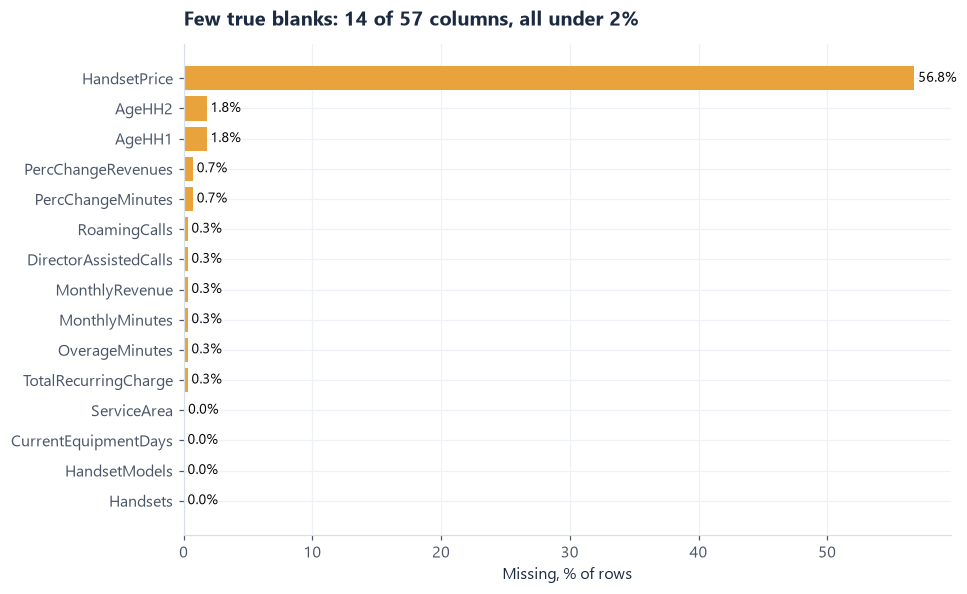

In [4]:
ax = audit.plot_missing(d.drop(columns=["CustomerID", "Churned"]), title="Few true blanks: 14 of 57 columns, all under 2%")
plt.show()

True blanks are rare, but **missing values hide behind codes**. Size every sentinel and odd value, with the churn rate
of the rows that carry it.

In [5]:
sentinels = {
    "HandsetPrice = 'Unknown'": d["HandsetPrice"].isna(),
    "AgeHH1 = 0 (age not known)": d["AgeHH1"] == 0,
    "IncomeGroup = 0 (income not known)": d["IncomeGroup"] == 0,
    "Usage block blank (revenue, minutes, overage...)": d["MonthlyRevenue"].isna(),
    "Usage change blank (PercChangeMinutes)": d["PercChangeMinutes"].isna(),
    "CurrentEquipmentDays < 0": d["CurrentEquipmentDays"] < 0,
    "MonthlyRevenue <= 0": d["MonthlyRevenue"] <= 0,
    "TotalRecurringCharge < 0": d["TotalRecurringCharge"] < 0,
    "ServiceArea blank": d["ServiceArea"].isna(),
}
sent = pd.DataFrame({k: {"rows": int(m.sum()), "share": m.mean(), "churn_rate_flagged": d.loc[m, "Churned"].mean() if m.any() else np.nan,
                         "churn_rate_rest": d.loc[~m, "Churned"].mean()} for k, m in sentinels.items()}).T
sent["rows"] = sent["rows"].astype(int)
print(f"Months in service: min {d['MonthsInService'].min():.0f}, so every subscriber has at least 6 months of tenure (a left-truncated sample)")
print(f"'PercChangeMinutes' ranges {d['PercChangeMinutes'].min():,.0f} to {d['PercChangeMinutes'].max():,.0f}: an absolute change in minutes, not a percentage")
sent

Months in service: min 6, so every subscriber has at least 6 months of tenure (a left-truncated sample)
'PercChangeMinutes' ranges -3,875 to 5,192: an absolute change in minutes, not a percentage


,rows,share,churn_rate_flagged,churn_rate_rest
HandsetPrice = 'Unknown',28982,0.5678,0.3017,0.2704
AgeHH1 = 0 (age not known),13917,0.2726,0.3022,0.2829
IncomeGroup = 0 (income not known),12835,0.2514,0.3023,0.2834
"Usage block blank (revenue, minutes, overage...)",156,0.0031,0.4487,0.2877
Usage change blank (PercChangeMinutes),367,0.0072,0.5668,0.2862
CurrentEquipmentDays < 0,76,0.0015,0.1842,0.2883
MonthlyRevenue <= 0,9,0.0002,0.2222,0.2882
TotalRecurringCharge < 0,8,0.0002,0.2500,0.2882
ServiceArea blank,24,0.0005,0.5000,0.2881


The codes matter more than the blanks. Unknown handset price covers 57% of subscribers and churns slightly more (30.2%
vs 27.0%). The age and income zeros cover a quarter each. A blank usage block (156 subscribers) or usage change (367)
goes with 45-57% churn. Every subscriber has at least six months of tenure, so the data says nothing about churn in the
first six months.

Usage fields are heavy-tailed. Percentiles show where a few extreme accounts sit.

In [6]:
heavy = ["MonthlyRevenue", "MonthlyMinutes", "OverageMinutes", "RoamingCalls", "CustomerCareCalls", "DroppedBlockedCalls", "CurrentEquipmentDays"]
q = d[heavy].quantile([0.5, 0.9, 0.99, 0.999, 1.0]).T
q.columns = ["median", "p90", "p99", "p99.9", "max"]
q["max / p99"] = q["max"] / q["p99"]
q

,median,p90,p99,p99.9,max,max / p99
MonthlyRevenue,48.4600,103.7700,225.9630,454.4866,"1,223.3800",5.4141
MonthlyMinutes,366.0000,"1,197.0000","2,458.3000","3,804.4400","7,359.0000",2.9935
OverageMinutes,3.0000,115.0000,429.1000,"1,040.5500","4,321.0000",10.0699
RoamingCalls,0.0000,2.1000,21.5000,89.1000,"1,112.4000",51.7395
CustomerCareCalls,0.0000,5.3000,21.0000,50.0000,327.3000,15.5857
DroppedBlockedCalls,5.3000,24.3000,72.0000,160.2862,411.7000,5.7181
CurrentEquipmentDays,329.0000,732.0000,"1,147.0000","1,596.9100","1,812.0000",1.5798


**Audit decisions.**

* **Handset price "Unknown" (57%)** is a missing code. The ETL keeps it as -1 for the tree model; the challenger adds an
  explicit missing flag; the logistic pipeline imputes and flags it.
* **Age and income zeros** are missing codes too, but these demographics stay out of the model, as in the report
  (fairness, and they add little).
* **The usage block is blank for 156 subscribers, and usage change for 367; those subscribers churn at 57%.** A blank
  recent-usage field can be a *consequence* of leaving (an account winding down) rather than a cause. See the leakage
  section.
* **Negative handset ages (76) and non-positive revenue (9)** are data errors. Handset age is clipped at 0 in the
  engineered features; there are too few to matter.
* **Extremes stay in.** The max/p99 ratios of 3-15 are real heavy users (roaming, overage) rather than unit errors.
  Trees are insensitive to them; the logistic pipeline uses a log transform.
* No duplicate subscribers or rows.

## 3. The target and the over-sampling

28.8% of this sample churned. A real carrier loses about 2% of subscribers a month (that is an assumption here; the
original Duke tournament's representative sample is usually quoted near that level). Churners were over-sampled to
give modellers enough of them. Three consequences:

1. **Rates in this notebook are relative risk.** "45% of retention callers churn" means they churn at 1.6x the base
   rate, not that 45% of them leave next month.
2. **Ranking metrics survive.** AUC, lift and capture depend only on the ordering within each class, which
   over-sampling does not change.
3. **Probabilities and money do not.** A model trained here predicts on the sample's scale. Before any expected value
   (P(churn) x value x save rate - cost) is computed, the probabilities need a prior correction (notebook 02) and the
   backtest needs reweighting to the real churn rate (notebook 03).

In [7]:
odds_ratio = (F.ASSUMED_MONTHLY_CHURN / (1 - F.ASSUMED_MONTHLY_CHURN)) / (F.SAMPLE_CHURN / (1 - F.SAMPLE_CHURN))
print(f"Each churner in the sample stands for {F.ASSUMED_MONTHLY_CHURN / F.SAMPLE_CHURN:.3f} real churners and each stayer for "
      f"{(1 - F.ASSUMED_MONTHLY_CHURN) / (1 - F.SAMPLE_CHURN):.3f} real stayers; odds scale by {odds_ratio:.4f}")

Each churner in the sample stands for 0.069 real churners and each stayer for 1.377 real stayers; odds scale by 0.0504


## 4. Who churns? Rates with 95% Wilson intervals

The drivers the report and README quote (tenure, handset age, care and retention calls), plus usage change, handset
price and credit rating.

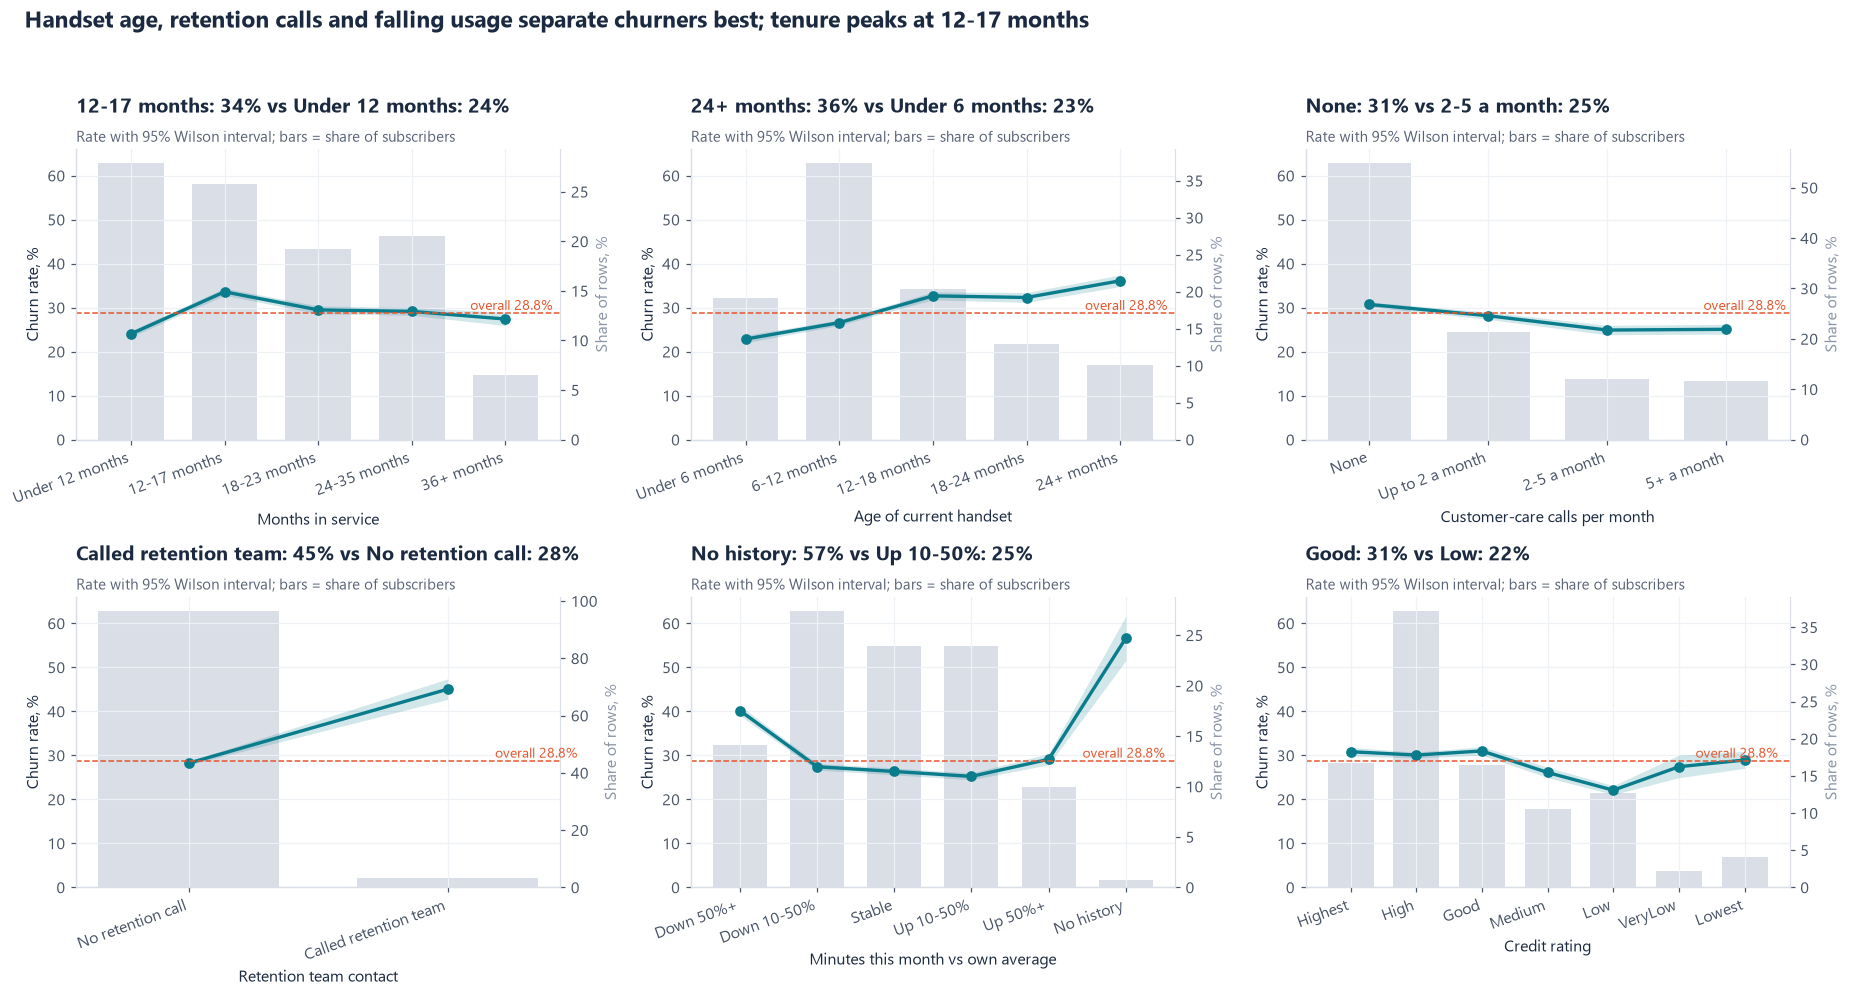

rows   rate  ci_low  ci_high
TenureBand       Under 12 months        14238 0.2403  0.2333   0.2474
                 12-17 months           13145 0.3360  0.3280   0.3441
                 18-23 months            9840 0.2949  0.2860   0.3040
                 24-35 months           10479 0.2914  0.2828   0.3002
                 36+ months              3345 0.2741  0.2593   0.2895
HandsetAgeBand   Under 6 months          9771 0.2286  0.2204   0.2371
                 6-12 months            19083 0.2658  0.2596   0.2722
                 12-18 months           10414 0.3268  0.3178   0.3358
                 18-24 months            6618 0.3231  0.3119   0.3344
                 24+ months              5160 0.3610  0.3480   0.3743
CareBand         None                   28020 0.3072  0.3019   0.3127
                 Up to 2 a month        10946 0.2817  0.2733   0.2902
                 2-5 a month             6187 0.2491  0.2385   0.2600
                 5+ a month              5894 0.2508  0.2399   0.2620
RetentionContact No retention call      49302 0.2824  0.2785   0.2864
                 Called retention team   1745 0.4504  0.4272   0.4739
UsageChange      Down 50%+               7186 0.4019  0.3906   0.4133
                 Down 10-50%            13996 0.2743  0.2670   0.2817
                 Stable                 12217 0.2635  0.2557   0.2714
                 Up 10-50%              12214 0.2523  0.2447   0.2601
                 Up 50%+                 5067 0.2911  0.2788   0.3038
                 No history               367 0.5668  0.5156   0.6165
CreditClass      Highest                 8522 0.3084  0.2987   0.3183
                 High                   18993 0.3007  0.2943   0.3073
                 Good                    8410 0.3101  0.3003   0.3201
                 Medium                  5357 0.2612  0.2496   0.2731
                 Low                     6499 0.2210  0.2110   0.2312
                 VeryLow                 1152 0.2743  0.2493   0.3008
                 Lowest                  2114 0.2895  0.2706   0.3092

In [8]:
v = d.assign(**B)
v["UsageChange"] = eda.binned(F.engineer(d)["minutes_change_rel"], bins=[-5.01, -0.5, -0.1, 0.1, 0.5, 5.01],
                              labels=["Down 50%+", "Down 10-50%", "Stable", "Up 10-50%", "Up 50%+"])
v["UsageChange"] = v["UsageChange"].replace("Missing", "No history")
v["HandsetPriceBand"] = eda.binned(d["HandsetPrice"], bins=[0, 40, 100, 200, 500], labels=["Under $40", "$40-99", "$100-199", "$200+"]).replace("Missing", "Unknown")
panels = [("TenureBand", "Months in service", F.BAND_ORDER["TenureBand"]),
          ("HandsetAgeBand", "Age of current handset", F.BAND_ORDER["HandsetAgeBand"]),
          ("CareBand", "Customer-care calls per month", F.BAND_ORDER["CareBand"]),
          ("RetentionContact", "Retention team contact", ["No retention call", "Called retention team"]),
          ("UsageChange", "Minutes this month vs own average", ["Down 50%+", "Down 10-50%", "Stable", "Up 10-50%", "Up 50%+", "No history"]),
          ("CreditClass", "Credit rating", F.BAND_ORDER["CreditClass"])]
fig, axes = plt.subplots(2, 3, figsize=(17, 9.2))
tabs = {}
for ax, (col, xl, order) in zip(axes.flat, panels):
    r = v.groupby(col)["Churned"].mean()
    hi_lab, lo_lab = r.reindex(order).dropna().idxmax(), r.reindex(order).dropna().idxmin()
    tabs[col] = eda.rate_by(v, col, "Churned", ax=ax, order=order, rate_label="Churn rate", xlabel=xl, rotate=20,
                            title=f"{hi_lab}: {r[hi_lab]:.0%} vs {lo_lab}: {r[lo_lab]:.0%}", subtitle="Rate with 95% Wilson interval; bars = share of subscribers")
    ax.set_ylim(0, 66)
fig.suptitle("Handset age, retention calls and falling usage separate churners best; tenure peaks at 12-17 months",
             x=0.02, ha="left", fontsize=15, fontweight="bold", color=PALETTE["ink"])
fig.tight_layout(rect=(0, 0, 1, 0.95))
savefig(fig, "01-churn-drivers", FIG); plt.show()
pd.concat(tabs)[["rows", "rate", "ci_low", "ci_high"]]

* **Tenure:** churn rises from 24.0% under 12 months to a 33.6% peak at 12-17 months, then eases to 27.4% after three
  years. That is the end of a one-year contract, when switching becomes free.
* **Handset age:** a steady climb from 22.9% (under 6 months) to 36.1% (24+ months). An upgrade offer is the obvious
  retention lever.
* **Usage change:** a fall of 50% or more means 40.2% churn, against 26.4% for stable usage. A blank history means 56.7%.
* **Retention-team callers:** 45.0% vs 28.2%. That is 1.6 times the base rate even after the team has spoken to them.
* **Counter-intuitive:** care calls go with lower churn (31% with none, 25% with 2-5 a month), and the lowest churn is in
  the low credit class (22%), plausibly because low-credit customers sit on contracts or deposits that make leaving
  costly.

All intervals are narrow (bands of 1,000+ subscribers), so these differences are not noise. They are associations,
though, not effects of the variable.

In [9]:
old = d["CurrentEquipmentDays"] >= 540
new = d["CurrentEquipmentDays"] < 180
ret = d["MadeCallToRetentionTeam"] == "Yes"
readme = pd.DataFrame({
    "README claim": ["Churn peaks at 12-17 months in service", "Handsets 18+ months old vs under 6 months", "Retention-team callers vs everyone else"],
    "reproduced": [f"12-17 months: {tabs['TenureBand'].loc['12-17 months', 'rate']:.1%} (highest band)",
                   f"{d.loc[old, 'Churned'].mean():.1%} vs {d.loc[new, 'Churned'].mean():.1%}",
                   f"{d.loc[ret, 'Churned'].mean():.1%} vs {d.loc[~ret, 'Churned'].mean():.1%}"]})
assert tabs["TenureBand"]["rate"].idxmax() == "12-17 months"
readme

,README claim,reproduced
0,Churn peaks at 12-17 months in service,12-17 months: 33.6% (highest band)
1,Handsets 18+ months old vs under 6 months,34.0% vs 22.9%
2,Retention-team callers vs everyone else,45.0% vs 28.2%


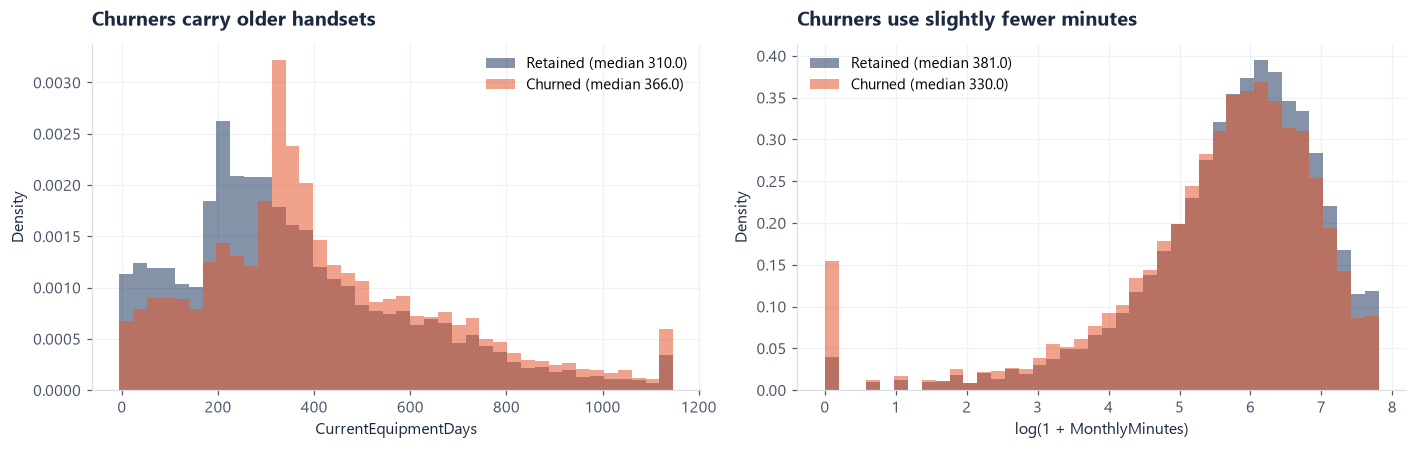

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
eda.dist_by_target(d, "CurrentEquipmentDays", "Churned", ax=a1, title="Churners carry older handsets")
eda.dist_by_target(d, "MonthlyMinutes", "Churned", ax=a2, log=True, title="Churners use slightly fewer minutes")
fig.tight_layout(); plt.show()

## 5. Correlation structure

Many usage fields count the same calls in different ways. The Spearman matrix over the numeric behaviour fields, and
the pairs above |rho| 0.8:

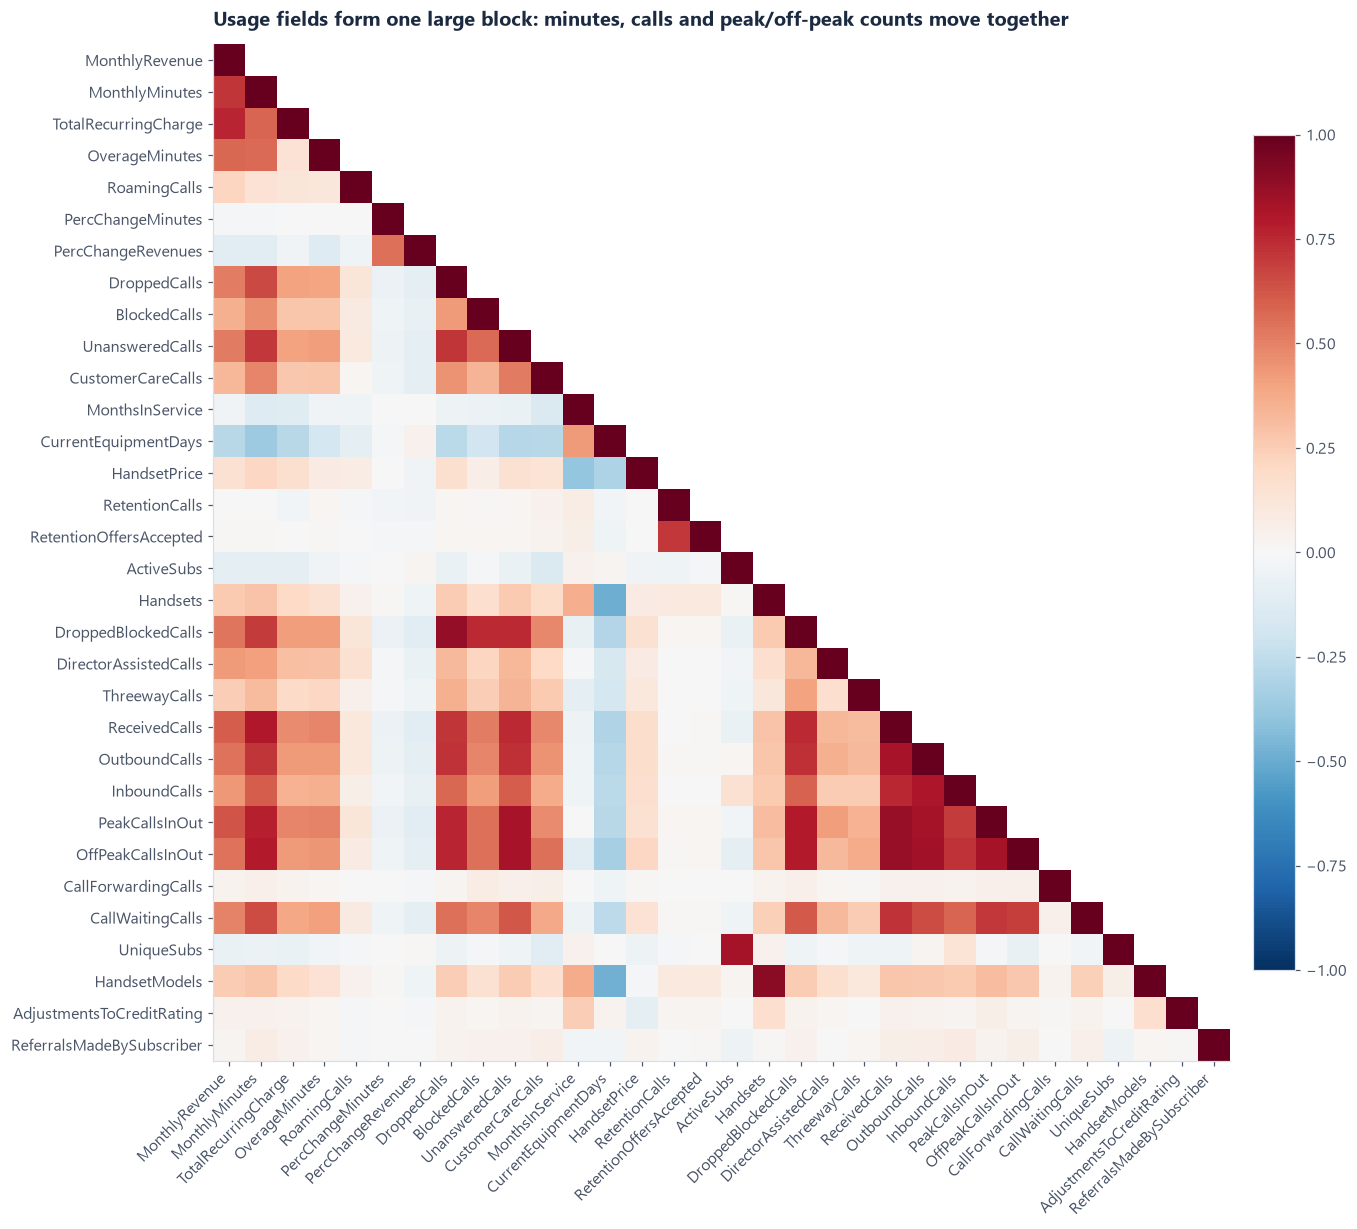

,feature_a,feature_b,rho
5,Handsets,HandsetModels,0.9054
1,DroppedCalls,DroppedBlockedCalls,0.8769
8,ReceivedCalls,OffPeakCallsInOut,0.8678
7,ReceivedCalls,PeakCallsInOut,0.8672
11,OutboundCalls,OffPeakCallsInOut,0.8435
4,ActiveSubs,UniqueSubs,0.8345
12,PeakCallsInOut,OffPeakCallsInOut,0.8328
10,OutboundCalls,PeakCallsInOut,0.8312
3,UnansweredCalls,OffPeakCallsInOut,0.8267
6,ReceivedCalls,OutboundCalls,0.8248


In [11]:
usage = F.NUM + F.EXTRA_NUM
corr = eda.corr_heatmap(d, usage, title="Usage fields form one large block: minutes, calls and peak/off-peak counts move together")
savefig(plt.gcf(), "01-correlation", FIG); plt.show()
pairs = eda.high_correlation_pairs(d, usage, threshold=0.8)
pairs

Thirteen pairs exceed 0.8. Handsets issued and handset models are near-duplicates (0.91). Dropped and dropped-or-blocked
calls overlap by construction (0.88). Received, outbound, peak and off-peak call counts form one block (0.80-0.87). The
19 ETL fields carry perhaps half a dozen independent signals.

Information value of each candidate, the ETL's features plus the engineered ratios, as a single-feature view:

In [12]:
cand = pd.concat([F.etl_matrix(d), F.engineer(d)], axis=1).assign(Churned=d["Churned"])
iv = eda.iv_table(cand, [c for c in cand.columns if c != "Churned"], "Churned")
iv.head(15)

,iv,strength
feature,,
MonthsInService,0.1392,medium
handset_age_years,0.1129,medium
CurrentEquipmentDays,0.1129,medium
minutes_change_rel,0.0696,weak
TotalRecurringCharge,0.0332,weak
revenue_per_minute,0.0319,weak
PercChangeMinutes,0.0301,weak
MonthlyMinutes,0.0253,weak
credit,0.0216,weak


No feature is even "strong" by the credit-scoring scale. Tenure (IV 0.14) and handset age (0.11) lead, and the
engineered usage change relative to the customer's own minutes (0.07) is the best behavioural signal, more than twice
the raw minute change (0.03).

## 6. Leakage audit: when is each field known?

Every field is measured over the months *before* the churn window, according to the source documentation, so none is
a post-outcome field by construction. Two families still need judgement: fields that record the customer's own *intent*
to leave, and blanks that may reflect an account already winding down.

In [13]:
screen = audit.leakage_screen(cand, [c for c in cand.columns if c != "Churned"], "Churned")
screen.head(10)

,single_feature_auc,direction,review
feature,,,
CurrentEquipmentDays,0.5745,+,
handset_age_years,0.5745,+,
revenue_per_minute,0.5484,+,
minutes_change_rel,0.5440,-,
TotalRecurringCharge,0.5425,-,
MonthlyMinutes,0.5395,-,
recurring_share,0.5311,-,
PercChangeMinutes,0.5310,-,
CustomerCareCalls,0.5303,-,


In [14]:
fam = {"Retention-team contact (MadeCallToRetentionTeam = Yes)": ret, "Retention offer accepted before": d["RetentionOffersAccepted"] > 0,
       "No usage-change history": d["PercChangeMinutes"].isna(), "Care calls 5+ a month": d["CustomerCareCalls"] >= 5}
leak = pd.DataFrame({k: {"subscribers": int(m.sum()), "share": m.mean(), "churn_if_yes": d.loc[m, "Churned"].mean(), "churn_if_no": d.loc[~m, "Churned"].mean(),
                         "share_of_all_churners": d.loc[m, "Churned"].sum() / d["Churned"].sum()} for k, m in fam.items()}).T
leak

,subscribers,share,churn_if_yes,churn_if_no,share_of_all_churners
Retention-team contact (MadeCallToRetentionTeam = Yes),"1,745.0000",0.0342,0.4504,0.2824,0.0534
Retention offer accepted before,881.0000,0.0173,0.4109,0.2860,0.0246
No usage-change history,367.0000,0.0072,0.5668,0.2862,0.0141
Care calls 5+ a month,"5,894.0000",0.1155,0.2508,0.2931,0.1005


**Leakage decisions.**

* **The screen finds no leak.** No feature exceeds a single-feature AUC of 0.58, so there is no near-perfect predictor
  and no sign of an outcome field. It also means the model must combine many weak signals.
* **Retention-team contact is kept, as a symptom.** The call is recorded before the churn window, so it is known when
  the list is scored and is a legitimate predictor. It is also the customer announcing an intent to leave, and these
  3.4% of subscribers (5.3% of churners) are already in the retention team's hands. Notebook 02 measures how much of the
  model's AUC depends on it; a model that mostly re-finds people who already called adds little. In the campaign, these
  subscribers belong to the retention team's own process and should not be counted as model wins.
* **A blank usage history is a possible consequence of leaving** (an account suspended or ported before the snapshot
  closed): 367 subscribers churning at 57%. It is only 1.4% of churners, so it cannot carry much of the AUC. It is kept as
  a flag and its effect is measured in notebook 02.
* **Care calls are not a leak, and they point the other way from the folklore.** Subscribers with 5+ care calls a month
  churn at 25%, those with none at 31%. Callers are engaged customers; the silent ones are the risk.

## 7. What EDA changed in the plan

* **Expect a modest AUC and judge the model on money.** The strongest single feature reaches AUC 0.57 and IV 0.14. Lift at
  the top of the list, and value captured, are the metrics that decide whether the model is worth running.
* **Handle the codes explicitly.** Handset price "Unknown" gets a flag, the blank usage block is kept as missing for the
  trees and imputed with a flag for the logistic model, and negative handset ages are clipped.
* **Engineer ratios that normalise behaviour by the customer's own level.** Usage change relative to the customer's own
  minutes (falling 50%+ means 40% churn), overage share, revenue per minute, dropped calls per call and care calls per
  100 calls.
* **Collinearity.** Thirteen pairs exceed |rho| 0.8 (handsets and handset models at 0.91, the call-count block). Trees cope,
  the logistic model needs regularisation, and SHAP credit should be read by family.
* **Correct the prior before any money.** Rescale probabilities from the 28.8% sample rate to an assumed 2% monthly churn,
  and reweight the economics backtest the same way.
* **Keep the ETL's split.** The data is a single snapshot with no dates, so out-of-time validation is impossible. A
  stratified random 70/30 split is the honest best here, and the model card states the limitation.
* **Fairness.** Age, marital status, occupation and household fields stay out, as in the report. Segment performance is
  checked by credit class, tenure and revenue band.

In [15]:
report.update_metrics(METRICS, "01_eda", {
    "subscribers": len(d), "churn_rate_sample": float(d["Churned"].mean()), "assumed_monthly_churn": F.ASSUMED_MONTHLY_CHURN,
    "churn_by_tenure": {k: float(v_) for k, v_ in tabs["TenureBand"]["rate"].items()},
    "churn_old_vs_new_handset": [float(d.loc[old, "Churned"].mean()), float(d.loc[new, "Churned"].mean())],
    "churn_retention_callers_vs_rest": [float(d.loc[ret, "Churned"].mean()), float(d.loc[~ret, "Churned"].mean())],
    "churn_usage_missing": float(d.loc[d["PercChangeMinutes"].isna(), "Churned"].mean()),
    "high_correlation_pairs": int(len(pairs)), "max_single_feature_auc": float(screen["single_feature_auc"].max()),
})
print("metrics written")

metrics written
